## Import Models

In [3]:
import pandas as pd
import numpy as np
import joblib
import os

# Load training and testing data
X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

# Load preprocessing pipeline
preprocessor = joblib.load("../models/preprocessor.pkl")

print("Data loaded successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Data loaded successfully!
X_train: (1600, 15)
X_test: (400, 15)


## import Classification Models

In [4]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

## Define the selected Models

In [5]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

## Model Training & Cross Validation

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    # Create complete pipeline
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Cross Validation
    scores = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean_F1_Macro": scores.mean(),
        "Std_F1_Macro": scores.std()
    })

    print(f"{name}: {scores.mean():.4f}")

# Results DataFrame
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Mean_F1_Macro",
    ascending=False
)

display(results_df)

Logistic Regression: 0.7644
Decision Tree: 0.5931
Random Forest: 0.6993
KNN: 0.6139
SVM: 0.7325
Gradient Boosting: 0.7054


,Model,Mean_F1_Macro,Std_F1_Macro
0,Logistic Regression,0.764353,0.021291
4,SVM,0.732457,0.013543
5,Gradient Boosting,0.705387,0.019583
2,Random Forest,0.699267,0.012802
3,KNN,0.613907,0.018648
1,Decision Tree,0.593064,0.022650


## Performance Visualisation

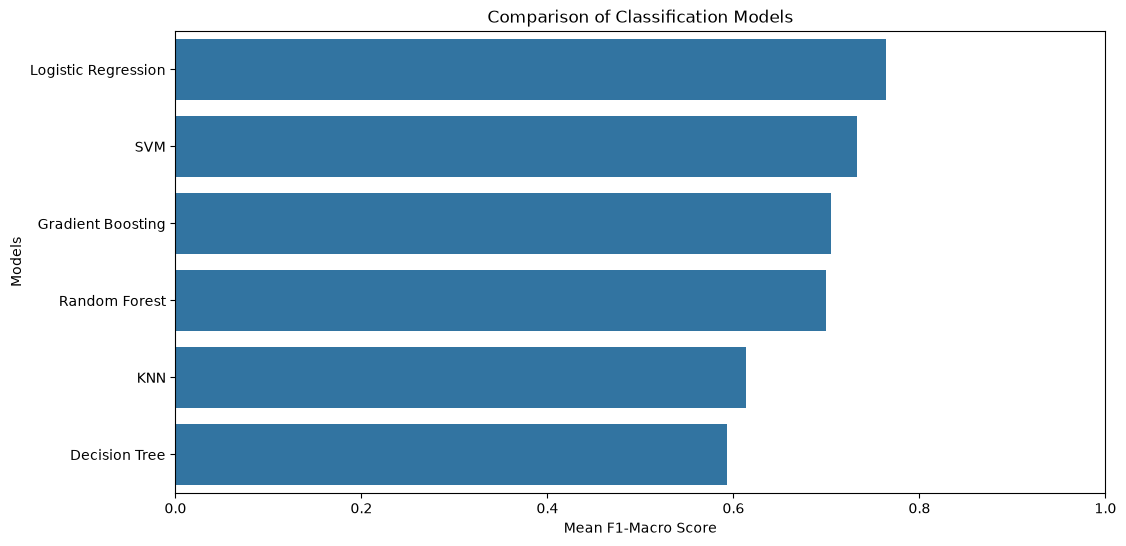

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Mean_F1_Macro",
    y="Model"
)

plt.title("Comparison of Classification Models")
plt.xlabel("Mean F1-Macro Score")
plt.ylabel("Models")
plt.xlim(0, 1)

plt.show()

## Best Model Selection

In [8]:
best_model_name = results_df.iloc[0]["Model"]

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print(
    "Best CV F1-Macro:",
    results_df.iloc[0]["Mean_F1_Macro"]
)

Best Model: Logistic Regression
Best CV F1-Macro: 0.7643534663032411


## Final Training

In [10]:
best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", best_model)
])

# Train best model
best_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Gender','Year_of_Study',...,'Part_Time_Job','Diet_Quality', 'Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

In [11]:
# Predictions
y_pred = best_pipeline.predict(X_test)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("Best Model:", best_model_name)
print("------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Best Model: Logistic Regression
------------------------------
Accuracy:  0.7125
Precision: 0.7191
Recall:    0.7115
F1-Score:  0.7144


In [12]:
print(classification_report(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

              precision    recall  f1-score   support

         Low       0.77      0.74      0.76       125
      Medium       0.56      0.62      0.59       132
        High       0.83      0.77      0.80       143

    accuracy                           0.71       400
   macro avg       0.72      0.71      0.71       400
weighted avg       0.72      0.71      0.72       400



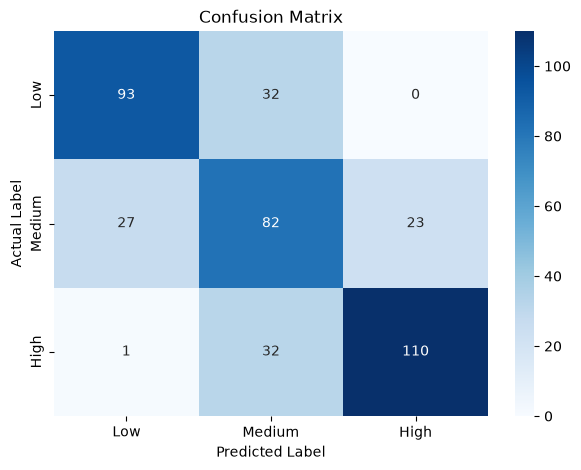

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()